In [14]:
import numpy as np
import pandas as pd
import random 
from sklearn.datasets import make_classification

In [15]:
X,y = make_classification(n_features=5, n_redundant=0, n_informative=5,n_clusters_per_class=1)

In [16]:
df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()

(100, 6)


,col1,col2,col3,col4,col5,target
0,0.154987,0.997834,0.370007,-0.480289,-0.776970,0
1,1.771578,0.556363,0.399998,-0.566023,-0.382686,0
2,-1.755630,1.396790,-1.394342,-0.737489,0.793482,1
3,1.772645,2.969391,0.081781,-0.151482,-2.033144,0
4,0.107008,1.575896,-0.871245,-2.196352,2.112478,1


In [17]:
# function for row sampling

def sample_rows(df,percent):
  return df.sample(int(percent*df.shape[0]),replace=True)

In [18]:
# function for feature sampling
def sample_features(df,percent):
  cols = random.sample(df.columns.tolist()[:-1],int(percent*(df.shape[1]-1)))
  new_df = df[cols]
  new_df['target'] = df['target']
  return new_df

In [19]:
# function for combined sampling
def combined_sampling(df,row_percent,col_percent):
    new_df = sample_rows(df,row_percent)
    return sample_features(new_df,col_percent)

In [20]:
df1 = combined_sampling(df,0.5,0.5)

In [21]:
df2 = combined_sampling(df,0.5,0.5)

In [22]:
df3 = combined_sampling(df,0.5,0.5)

In [23]:
print(df1.columns)
print(df2.columns)
print(df3.columns)

Index(['col2', 'col4', 'target'], dtype='str')
Index(['col2', 'col1', 'target'], dtype='str')
Index(['col4', 'col5', 'target'], dtype='str')


In [24]:
df3

,col4,col5,target
45,-0.931165,-1.553204,0
63,-0.567795,1.127945,1
35,-1.365241,-1.934741,0
58,-0.095076,1.675925,1
0,-0.480289,-0.776970,0
30,-1.827157,-0.155646,0
69,-1.319003,0.342784,1
42,-1.245900,0.544387,0
14,-1.597679,0.460332,1
37,-2.454575,1.997995,1


In [25]:
from sklearn.tree import DecisionTreeClassifier
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [26]:
clf1.fit(df1.iloc[:,0:2],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:2],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:2],df3.iloc[:,-1])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [27]:
from sklearn.tree import plot_tree

[Text(0.2916666666666667, 0.95, 'x[1] <= -1.979\ngini = 0.493\nsamples = 50\nvalue = [22.0, 28.0]'),
 Text(0.2361111111111111, 0.85, 'gini = 0.0\nsamples = 10\nvalue = [0, 10]'),
 Text(0.2638888888888889, 0.8999999999999999, 'True  '),
 Text(0.3472222222222222, 0.85, 'x[1] <= -1.682\ngini = 0.495\nsamples = 40\nvalue = [22, 18]'),
 Text(0.3194444444444444, 0.8999999999999999, '  False'),
 Text(0.2916666666666667, 0.75, 'gini = 0.0\nsamples = 7\nvalue = [7, 0]'),
 Text(0.4027777777777778, 0.75, 'x[0] <= 2.365\ngini = 0.496\nsamples = 33\nvalue = [15, 18]'),
 Text(0.3472222222222222, 0.65, 'x[0] <= -0.42\ngini = 0.459\nsamples = 28\nvalue = [10, 18]'),
 Text(0.1111111111111111, 0.55, 'x[1] <= -1.096\ngini = 0.32\nsamples = 5\nvalue = [4, 1]'),
 Text(0.05555555555555555, 0.45, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.16666666666666666, 0.45, 'x[0] <= -0.617\ngini = 0.444\nsamples = 3\nvalue = [2, 1]'),
 Text(0.1111111111111111, 0.35, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),


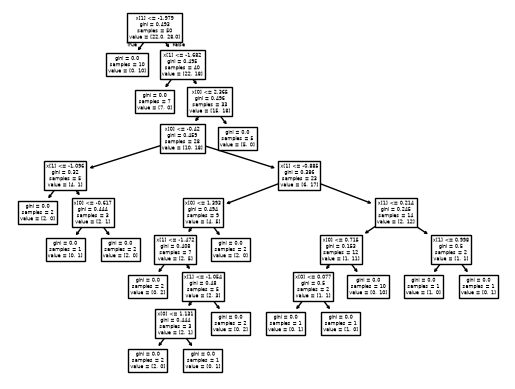

In [28]:
plot_tree(clf1)

[Text(0.4230769230769231, 0.9166666666666666, 'x[1] <= -0.182\ngini = 0.499\nsamples = 50\nvalue = [24, 26]'),
 Text(0.15384615384615385, 0.75, 'x[0] <= 1.427\ngini = 0.087\nsamples = 22\nvalue = [1, 21]'),
 Text(0.28846153846153844, 0.8333333333333333, 'True  '),
 Text(0.07692307692307693, 0.5833333333333334, 'gini = 0.0\nsamples = 16\nvalue = [0, 16]'),
 Text(0.23076923076923078, 0.5833333333333334, 'x[0] <= 1.774\ngini = 0.278\nsamples = 6\nvalue = [1, 5]'),
 Text(0.15384615384615385, 0.4166666666666667, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.3076923076923077, 0.4166666666666667, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.6923076923076923, 0.75, 'x[0] <= 0.751\ngini = 0.293\nsamples = 28\nvalue = [23, 5]'),
 Text(0.5576923076923077, 0.8333333333333333, '  False'),
 Text(0.5384615384615384, 0.5833333333333334, 'x[1] <= 1.537\ngini = 0.469\nsamples = 8\nvalue = [5, 3]'),
 Text(0.46153846153846156, 0.4166666666666667, 'x[0] <= -1.017\ngini = 0.48\nsamples = 5\nval

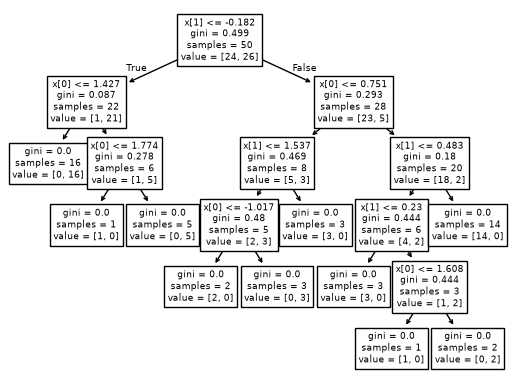

In [29]:
plot_tree(clf2)

[Text(0.5555555555555556, 0.9375, 'x[1] <= -0.772\ngini = 0.497\nsamples = 50\nvalue = [27, 23]'),
 Text(0.4444444444444444, 0.8125, 'gini = 0.0\nsamples = 21\nvalue = [21, 0]'),
 Text(0.5, 0.875, 'True  '),
 Text(0.6666666666666666, 0.8125, 'x[1] <= 1.374\ngini = 0.328\nsamples = 29\nvalue = [6, 23]'),
 Text(0.6111111111111112, 0.875, '  False'),
 Text(0.5555555555555556, 0.6875, 'x[0] <= 1.078\ngini = 0.42\nsamples = 20\nvalue = [6, 14]'),
 Text(0.4444444444444444, 0.5625, 'x[1] <= 0.519\ngini = 0.48\nsamples = 15\nvalue = [6, 9]'),
 Text(0.2222222222222222, 0.4375, 'x[0] <= -1.739\ngini = 0.346\nsamples = 9\nvalue = [2, 7]'),
 Text(0.1111111111111111, 0.3125, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.3333333333333333, 0.3125, 'x[0] <= -0.936\ngini = 0.219\nsamples = 8\nvalue = [1, 7]'),
 Text(0.2222222222222222, 0.1875, 'gini = 0.0\nsamples = 5\nvalue = [0, 5]'),
 Text(0.4444444444444444, 0.1875, 'x[0] <= -0.766\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.3333333

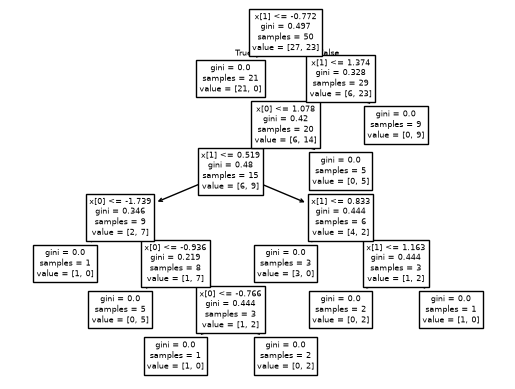

In [30]:
plot_tree(clf3)

In [31]:
clf1.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [32]:
clf2.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [33]:
clf3.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

C:\Users\jaggi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [34]:
df.sample(14,replace=True)

,col1,col2,col3,col4,col5,target
84,2.374535,-1.066985,1.527924,-1.478140,0.602290,0
9,-2.086346,1.241926,-0.969045,-1.562047,0.983921,1
47,1.197403,-0.985515,1.445777,-1.605508,-0.164425,0
45,0.865006,1.537289,1.014730,-0.931165,-1.553204,0
46,-2.010875,1.697527,-1.428220,-0.704767,1.848354,1
93,-0.288344,0.655597,2.406407,-1.554928,0.922238,1
12,0.319071,3.060957,0.140423,0.005818,-0.680893,0
67,1.208325,-1.238113,1.169549,-1.399640,0.682123,0
85,2.855654,1.449906,0.052539,-0.212491,-1.738566,0
12,0.319071,3.060957,0.140423,0.005818,-0.680893,0
